In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
import random
import numpy as np
from attrdict import AttrDict

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init

from torch.autograd import Variable
from torch.nn.utils import parameters_to_vector

from functorch import vmap,grad,jacfwd,jacrev
from functorch import make_functional, make_functional_with_buffers



from torch.distributions.normal import Normal
from torch.distributions.multivariate_normal import MultivariateNormal as MVN
from torch.distributions.lowrank_multivariate_normal import LowRankMultivariateNormal as LowMVN
from torch.distributions.kl import kl_divergence

eps_pred   = 1e-6
eps_nan    = 1e-6
large_val  = 1e6

eps        = 1e-6
eps_zitter = eps
eps_log    = eps
eps_clamp  = eps
eps_nan    = eps 
eps_eigv   = eps
eps_zeros  = eps

nan_val = 0
posinf_val = 1e1
neginf_val = -1e1
nanstd_val = 1e-2


def _num_parameters(model):
    return sum([p.numel() for p in model.parameters()])


def transform_logstd(logstd):
    return 1e-6 + F.softplus(logstd, beta=1, threshold=20)


def build_MVN_Low(params:list , asprior=True):
    qf_mean,qf_Lcov = params
    zitter_mat = eps_zitter*torch.ones_like(qf_mean).to(qf_mean.device)                    
    if asprior:
        qf_dist = LowMVN(qf_mean.detach().clone(), qf_Lcov.detach().clone(), zitter_mat.detach().clone() )                        
    else:
        qf_dist = LowMVN(qf_mean ,qf_Lcov, zitter_mat)                                
    return qf_dist


def build_MVN_Full(params:list , asprior=True):
    qf_mean,qf_cov = params
    zitter_mat = eps_zitter*torch.eye(qf_mean.shape[-1]).to(qf_mean.device)[None,...]                    
    if asprior:    
        qf_dist = MVN(qf_mean.detach().clone() , (qf_cov +  zitter_mat).detach().clone()   )                        
    else:
        qf_dist = MVN(qf_mean , qf_cov +  zitter_mat)                               
    return qf_dist



def build_MVN_Diag(params:list , asprior=True, eps_zitter=1e-4):
    qf_mean,qf_std = params
    zitter_mat = eps_zitter*torch.ones_like(qf_mean).to(qf_mean.device)                    
    if asprior:    
        qf_dist = Normal(qf_mean.detach().clone() , (qf_std +  zitter_mat).detach().clone()   )                        
    else:
        qf_dist = Normal(qf_mean , qf_std +  zitter_mat)                               
    return qf_dist

    
def build_MVN(params:list, asprior=True, Lowrank=True, Diag=False):
    if Diag:
        return  build_MVN_Diag(params,asprior)   
    else:
        return  build_MVN_Low(params,asprior) if Lowrank  else build_MVN_Full(params,asprior)        
    
def compute_kl(params_qf, params_pf , Lowrank=True, Diag=False):
    qf_dist = build_MVN( params_qf, asprior=False, Lowrank=Lowrank, Diag=Diag)
    pf_dist = build_MVN( params_pf, asprior=True,  Lowrank=Lowrank, Diag=Diag)
    #breakpoint()
    return kl_divergence(qf_dist,pf_dist).mean(dim=0,keepdim=True)


def _num_parameters(model):
    return sum([p.numel() for p in model.parameters()])


        
               

class Hiddenfeature_Mixture_Module(nn.Module):     
    def __init__(self, nfeature: int, nlabel: int , usediagcov=True, gamma=0.99,eps_zitter=1e-4):
        super(Hiddenfeature_Mixture_Module,self).__init__()
        
        self.nfeature = nfeature
        self.nlabel = nlabel
        self.eps_zitter = eps_zitter
        #self.gamma = gamma
        self.usediagcov = usediagcov
        
        # per epoch        
        self.static_cnt_sum    =  nn.Parameter( torch.zeros(self.nlabel), requires_grad=False )        
        self.static_mean_sum   =  nn.Parameter( torch.zeros(self.nlabel, self.nfeature), requires_grad=False )
        self.static_cov_sum    =  nn.Parameter( torch.zeros(self.nlabel, self.nfeature) , requires_grad=False )        
        return 

    
    #def __repr__(self):
    def extra_repr(self):        
        msg = 'nlabel: {}, \n'.format(self.nlabel)
        msg += 'nfeature: {}, \n'.format(self.nfeature)
        return msg[:-1]
    
           
       
    def update_layers_static_batch(self, h_feature, y, eps_zitter=1e-4):
        # set idx_per_label        
        idx_per_label =  [(y == k)  for k in range(self.nlabel) ]  
        
        # compute emirical mean and cov
        static_mean_sum, static_cov_sum = [],[]        
        for idx_current in idx_per_label:
            if idx_current.sum() > 0 :        
                # compute mean
                k_label_mean_sum = h_feature[idx_current].sum(dim=0,keepdim=True) #(1,nfilters)
                k_label_mean     = k_label_mean_sum / idx_current.sum()
                
                # compute cov
                k_delta_cov      = h_feature[idx_current] - k_label_mean    #(nb,nfilters)
                k_label_cov_sum  = (k_delta_cov**2).sum(dim=0,keepdim=True)  #(1,nfilters)
            else:
                k_label_mean_sum = torch.zeros(1,self.nfeature).to(y.device) 
                k_label_cov_sum  = torch.zeros(1,self.nfeature).to(y.device)                               
                
            static_mean_sum.append(k_label_mean_sum)     
            static_cov_sum.append(k_label_cov_sum) 
        
        static_mean_sum = torch.cat(static_mean_sum, dim=0)   #(nlables, nfilters)
        static_cov_sum  = torch.cat(static_cov_sum, dim=0)    #(nlables, nfilters)
        static_cnt      = torch.tensor([idx_current.sum() for idx_current in idx_per_label]).to(y.device) #(nlables)        
        

        # compute layer feature
        nb = len(y)        
        
        ## update static params per batch
        self.static_cnt_sum.data     +=  static_cnt.data
        self.static_mean_sum.data    +=  static_mean_sum.data
        self.static_cov_sum.data     +=  static_cov_sum.data
        
        return 
    
    def get_static_params(self):

        mean               = self.static_mean_sum.data                          / self.static_cnt_sum.data.view(-1,1)
        mean_shared        = self.static_mean_sum.data.sum(dim=0,keepdims=True) / self.static_cnt_sum.data.sum()
        cov_shared         = self.static_cov_sum.data.sum(dim=0)                / self.static_cnt_sum.data.sum()  
        
        
        # if self.usediagcov:
        cov_shared         = cov_shared + self.eps_zitter
        precision_shared   = 1 / cov_shared 

        return mean,mean_shared,precision_shared
        

    def compute_mh_distance_batch(self, h_feature , datatype = 'x' ,overclass=False, usenormalize=True):    
        layers_mean, _ , layers_precision = self.get_static_params()
                           

        ## compute distance                           
        # if self.usediagcov :
        delta_h = h_feature[:,None,:] - layers_mean[None,:,:]
        squareterm_inner =  torch.pow(delta_h,2) * layers_precision[None,None,...]  #(nb,ncls,nhdim)*(1,1,nhdim) = (nb,ncls,nhdim)
        mh_distance_over_class  = -1*squareterm_inner.sum(dim=-1)       

        if usenormalize:
            mh_distance_over_class  = mh_distance_over_class / h_feature.size(-1)
        mh_distance, assigned_label = mh_distance_over_class.max(dim=-1)            

        if overclass:
            return mh_distance_over_class
        else:
            return mh_distance
        


In [3]:

def _weights_init(m):         
    if isinstance(m, nn.Conv2d):
        init.kaiming_normal(m.weight, mode='fan_out')
        try:
            if m.bias.any():
                init.constant(m.bias, 0)
        except:
            pass
            
    elif isinstance(m, nn.BatchNorm2d):
        init.constant(m.weight, 1)
        init.constant(m.bias, 0)
    elif isinstance(m, nn.Linear):
        init.normal(m.weight, std=1e-1)
        try:
            if m.bias.any():
                init.constant(m.bias, 0)
        except:
            pass
    else:
        pass
    return


class FBNN_SmallNet_Pro(nn.Module):

    def __init__(self, in_dim=2, out_dim=2, hidden_dim=100, nlabel=2, scalelogstd = -2, noiselogstd= 0.1 , priorstdout = 10. , temppeak=1.):

        super(FBNN_SmallNet_Pro, self).__init__()


        self.scalelogstd          = scalelogstd        
        self.priorstdout          = priorstdout       

        self.temperature_distance = 1e0
        
        
    
        mixture_module = Hiddenfeature_Mixture_Module(nfeature=hidden_dim, nlabel=nlabel, usediagcov=True)
        self.mixture_module   = mixture_module     


        layer1 = nn.Linear(in_dim, hidden_dim)
        deterministic_nn = [layer1] + [nn.Linear(hidden_dim, hidden_dim)]*3


        layer2 = nn.Linear(hidden_dim, out_dim)
        stochastic_nn    = [layer2,
                           ]       

        self.act = nn.ReLU()
        
            

        self.deterministic_nn = nn.Sequential(*deterministic_nn)   
        self.stochastic_nn    = nn.Sequential(*stochastic_nn)                       
        self.noise_logstd     = nn.Parameter(torch.tensor(np.log(noiselogstd + eps_log))  , requires_grad=True )    ##use for regression

        self.deterministic_nn.apply(_weights_init)          
        self.stochastic_nn.apply(_weights_init)        

        self.setup_parameters()
        self.setup_functiondist()
        
        
    def deterministic_nn_forward(self,x):
        h = self.deterministic_nn[0](x)
        h = self.act(h)        
        
        for i_layer in self.deterministic_nn[1:]:
            tmp_h = self.act(i_layer(h)) 
            h     = tmp_h + h   
        return h
        

                
    def setup_parameters(self):        
        self.num_params_d    = _num_parameters(self.deterministic_nn)          
        self.num_params_s    = _num_parameters(self.stochastic_nn)  

        self.params_q_logstd =  nn.ParameterList([nn.Parameter(torch.empty_like(ith_param).uniform_(self.scalelogstd,self.scalelogstd+1)  ,requires_grad=True )  for ith_param in self.stochastic_nn.parameters()])
         
        #set prior params        
        self.params_p_mean   = nn.ParameterList( [nn.Parameter(torch.zeros_like(ith_param) ,requires_grad=False )  for ith_param in self.stochastic_nn.parameters()] )
        self.params_p_logstd = nn.ParameterList([nn.Parameter(torch.ones_like(ith_param)  ,requires_grad=False )  for ith_param in self.stochastic_nn.parameters()]) 
        return    
    
    
    def setup_functiondist(self):    
        func_model, _ , buffers = make_functional_with_buffers(self.stochastic_nn)                
        self.func_model         =  lambda params, x_in : func_model(params, buffers, x_in) 
        self.flag_setup         = True         
        return         


    #def extra_repr(self):
    def __repr__(self):        
        msg =  'deterministic NN: {} \n'.format(self.deterministic_nn)
        msg += 'stochastic NN: {} \n'.format(self.stochastic_nn)       
        msg += 'scalelogstd: {} \n'.format(self.scalelogstd) 
        msg += '#qmu: {}, #qstd: {} \n'.format(_num_parameters(self.stochastic_nn),_num_parameters(self.params_q_logstd))
        msg += '#pmu: {}, #pstd: {} \n'.format(_num_parameters(self.params_p_mean),_num_parameters(self.params_p_logstd))
        return msg[:-1]
        
               
    
    
    def compute_funcdist_wo_jacobian(self, x , param_q_mean, param_q_logstd, no_grad_jacobian=False ):

        #self.setup_functiondist() if not self.flag_setup else 1        
        assert len(param_q_logstd) <=2
        
        # compute f_mean
        h      = self.deterministic_nn_forward(x) 
        f_mean = self.func_model(param_q_mean, h ) 

        # use values of jacobian without grad
        if no_grad_jacobian:
            h = h.detach().clone()

        # comopute f_std
        param_q_std        = [transform_logstd(ith_q_logstd) for ith_q_logstd in param_q_logstd ]                
        f_var_linear_inner = param_q_std[0][None,...]*h[:,None,:] #(1,ydim,nparams)*(nb,1,nparams) = (nb,ydim,nparams)
        f_var_linear       = torch.pow(f_var_linear_inner,2).sum(dim=-1) #(nb,ydim)

        if len(param_q_logstd) == 2:               
            f_var_bias = torch.pow( param_q_std[1][None,...], 2)  
        else :  
            f_var_bias = 0.0
        f_diagcov = f_var_linear + f_var_bias #(nb,ydim)
    
        return f_mean, f_diagcov, h
    
    
    
    def compute_funcdist_wo_jacobian_h(self, h , param_q_mean, param_q_logstd , no_grad_jacobian=True ):

        #self.setup_functiondist() if not self.flag_setup else 1        
        assert len(param_q_logstd) <=2
        

        
        f_mean = self.func_model(param_q_mean, h ) 



        # use values of jacobian without grad
        if no_grad_jacobian:
            h = h.detach().clone()

        # comopute f_std        
        param_q_std        = [transform_logstd(ith_q_logstd) for ith_q_logstd in param_q_logstd ]                
        f_var_linear_inner = param_q_std[0][None,...]*h[:,None,:] #(1,ydim,nparams)*(nb,1,nparams) = (nb,ydim,nparams)
        f_var_linear       = torch.pow(f_var_linear_inner,2).sum(dim=-1) #(nb,ydim)

        if len(param_q_logstd) == 2:               
            f_var_bias = torch.pow( param_q_std[1][None,...], 2)  
        else :  
            f_var_bias = 0.0
        f_diagcov = f_var_linear + f_var_bias #(nb,ydim)
    
        return f_mean, f_diagcov, h
    

    def build_logit_samples_from_fdist(self, f_mean,f_std,nfsample=1):
        eps = torch.randn(nfsample,*f_mean.shape).to(f_mean.device) #(nfsample,nb,ydlim)
        logits_samples = f_mean[None,...]  + f_std[None,...]*eps
        return logits_samples


       
       

    def compute_logit_samples(self, x , nfsample = 1, use_bayes=True):                                       

        # set train mode
        self.eval()                                             

        # get params
        param_q_mean, param_q_logstd   = list(self.stochastic_nn.parameters()) ,  list(self.params_q_logstd)             

        # compute logit samples            
        qf_mean_x , qf_diagcov_x, _    = self.compute_funcdist_wo_jacobian( x, param_q_mean, param_q_logstd )   #without jacobian computation         
        qf_std_x                       = torch.sqrt(qf_diagcov_x)                              

        # compute noise params
        f_var  = torch.exp(2*self.noise_logstd)*torch.ones_like(qf_mean_x).to(qf_mean_x.device)
                                                                                        
        
        if not use_bayes:          
            qf_mean_x = qf_mean_x[None,...]
            #f_var   = f_var[None,...]              
            return qf_mean_x
                                
        else:
            f_samples = self.build_logit_samples_from_fdist(qf_mean_x, qf_std_x, nfsample=nfsample)  
            #f_var   =  f_var[None,...].repeat(nfsample,1,1)                      
            return f_samples
                                            
                                            

    ## inference using the adversarial hidden features 
    def compute_logit_samples_v2(self, x , y=None, intrain=True,  use_bayes=True, update_h = False,  configs=None):                                       

        # set train mode
        self.train() if intrain else self.eval()                                             

        # get params
        param_q_mean, param_q_logstd  = list(self.stochastic_nn.parameters()) ,  list(self.params_q_logstd)             

        # compute logit samples            
        qf_mean_x , qf_diagcov_x, h_x  = self.compute_funcdist_wo_jacobian( x, param_q_mean, param_q_logstd )   #without jacobian computation         
        qf_std_x                      = torch.sqrt(qf_diagcov_x)              
                
        # compute noise params        
        f_var   = torch.exp(2*self.noise_logstd)*torch.ones_like(qf_mean_x).to(qf_mean_x.device)
        
        if not use_bayes:            
            ## update the parameters of the empirical hidden feature 
            if intrain and update_h and (y is not None):
                self.update_hidden_module_from_hx(h_x, y)                                 

            qf_mean_x = qf_mean_x[None,...]
            return qf_mean_x , h_x
                                
        else:
            nfsample  = configs.train.nfsample
            f_samples = self.build_logit_samples_from_fdist(qf_mean_x, qf_std_x, nfsample=nfsample)            
            return f_samples, h_x
        
               
       
       
       
    ## update mixture feature during training
    def update_hidden_module(self, x, y):
        h = self.deterministic_nn_forward(x)           
        self.mixture_module.update_layers_static_batch(h, y)
        return        
                
    ## update mixture feature during training
    def update_hidden_module_from_hx(self, h_x, y):
        self.mixture_module.update_layers_static_batch(h_x, y)
        return     
       
             
    
    def compute_kde_pfuncdist_from_h(self, ht, param_p_mean, param_p_logstd ,temperature=1e1, requires_grad=False ):
        h_mean, _, _       = self.mixture_module.get_static_params()
        h_mean             = h_mean.detach().clone()              #
        kde_ht             = self.mixture_module.compute_mh_distance_batch(ht ,overclass=True, usenormalize=True) ## -0.5*exp()
        kde_weight         = F.softmax( kde_ht , dim=-1)
        proj_ht            = (kde_weight[...,None]*h_mean[None,...]).sum(dim=1) #(nb,ncls,1)*(1,ncls,ndim) = (nb,ndim)

        f_mean             = self.func_model(param_p_mean, proj_ht)

        param_q_std        = [transform_logstd(ith_q_logstd) for ith_q_logstd in param_p_logstd ]                
        f_var_linear_inner = param_q_std[0][None,...]*proj_ht[:,None,:] #(1,ydim,nparams)*(nb,1,nparams) = (nb,ydim,nparams)
        f_var_linear       = torch.pow(f_var_linear_inner,2).sum(dim=-1) #(nb,ydim)
        
        
        
        if len(param_p_logstd) == 2 : #bias term exists
            f_var_bias         = torch.pow( param_q_std[1][None,...], 2)                 
        else:
            f_var_bias         = torch.tensor([0.0]).to(ht.device)

        f_diagcov          = f_var_linear + f_var_bias #(nb,ydim)


        ## revised prior induced by h_mean
        h_mean_square = (param_q_std[0][None,:,:])*(h_mean[:,None,:])    #(1,ncls,nparams) * (ncls,1,nparams)
        h_mean_square = (h_mean_square**2).sum(dim=-1)  #(ncls,ncls)

        phat_idx      = kde_weight.max(dim=-1)[1]
        Mhat          = h_mean_square[phat_idx] #(nb,ncls)

        f_diagcov     = 2*( Mhat + f_var_bias.reshape(1,-1) ) - f_diagcov  #(1,ydim) + (nb,ydim)
        f_diagcov     = f_diagcov.clamp(min=1e-12)
        f_diagcov     = (self.priorstdout**2)*f_diagcov

        
        if requires_grad:        
            # stop gradient
            return f_mean, f_diagcov, proj_ht
        else:
            # stop gradient
            return f_mean.detach().clone(), f_diagcov.detach().clone(), proj_ht.detach().clone()    
                            
                
        
    
            
    
    def compute_fdist(self, xc , topk=3, useswagparam=True):                

        self.train()                
    
        # compute "q" function space dist on context inputs        
        param_q_mean, param_q_logstd      = list(self.stochastic_nn.parameters()) ,  list(self.params_q_logstd)             
        qf_mean_xc , qf_diagcov_xc, h_xc  = self.compute_funcdist_wo_jacobian( xc, param_q_mean, param_q_logstd )   #without jacobian computation         
        qf_std_xc                         = torch.sqrt(qf_diagcov_xc)
        
        # compute "p" function space dist on context inputs        
        if not useswagparam:            
            pf_mean_xc =                1*torch.zeros_like(qf_mean_xc).to(xc.device)
            pf_std_xc  = self.priorstdout*torch.ones_like(qf_mean_xc).to(xc.device)            
        else:        

            ## compute "BMA" function space dist on context inputs        
            param_p_mean, param_p_logstd  = list(self.params_p_mean) ,  list(self.params_p_logstd) 
            pf_mean_xc , pf_diagcov_xc, _  = self.compute_kde_pfuncdist_from_h( h_xc, param_p_mean, param_p_logstd )      
            pf_mean_xc = pf_mean_xc.detach().clone()
            pf_std_xc  = self.priorstdout*torch.sqrt(pf_diagcov_xc).detach().clone()


            
        param_qf = (qf_mean_xc, qf_std_xc)    
        param_pf = (pf_mean_xc, pf_std_xc)

        return param_qf, param_pf, None                    
           
               
        
        
    def compute_sup_kl(self, params_qf, params_pf, weight=None, Lowrank=True, Diag=True, nctset=2, eps=1e-8):        
        def _compute_kl(params_qf, params_pf , Lowrank=True, Diag=False):
            qf_dist = build_MVN( params_qf, asprior=False, Lowrank=Lowrank, Diag=Diag)
            pf_dist = build_MVN( params_pf, asprior=True,  Lowrank=Lowrank, Diag=Diag)
            kl_div_qf_pf = kl_divergence(qf_dist,pf_dist)
            kl_div = kl_div_qf_pf.sum(dim=-1)
            return kl_div #(nb,)
        
        
        # set params
        qf_mean,qf_cov = params_qf
        pf_mean,pf_cov = params_pf

        # split ctxset
        num_batch = qf_mean.shape[0] // nctset
        idx_set = [torch.randperm(qf_mean.shape[0])[i*num_batch:(i+1)*num_batch] for i in range(nctset) ]

        # compute kl
        kl_divergence_list = []
        for i_set in idx_set:
            i_params_q = qf_mean[i_set] , qf_cov[i_set]
            i_params_p = pf_mean[i_set] , pf_cov[i_set]       
            i_kl_batch = _compute_kl(i_params_q, i_params_p, Lowrank=Lowrank, Diag=Diag )       
            if weight is None:            
                i_weight_kl_batch = i_kl_batch                
            else:
                i_weight          = weight[i_set]                       
                i_weight_kl_batch = i_weight*i_kl_batch
            kl_divergence_list.append( (i_weight_kl_batch).sum(dim=-1,keepdim=True) )

        kl_divergence_list = torch.cat(kl_divergence_list,dim=0)
        sup_kl             = (1 / num_batch)*kl_divergence_list.max()
        return torch.clamp(sup_kl,min=eps)    



    ## get the last layer weight parameters
    def get_current_p_params(self):
        return [i_param.data.detach().clone() for i_param in self.stochastic_nn.parameters()]  
           
    ## update the last layer weight parameters
    def update_params_p(self,param_p_mean,param_p_logstd,base_nan=-12.):

        for i_p_mean,i_p_logstd,i_u_p_mean,i_u_p_logstd in zip(self.params_p_mean,
                                                               self.params_p_logstd,
                                                               param_p_mean,
                                                               param_p_logstd):
            i_p_mean.data=i_u_p_mean.data
            i_p_logstd.data= torch.nan_to_num(i_u_p_logstd.data, nan= base_nan) 
        return             
                
    


    
    ##-------------------------------------------------------------
    ## build the adversional context hidden feature
    ##-------------------------------------------------------------
    
    def compute_h_x_grad(self,h_x):
        h_x_copy    = h_x.detach().clone().requires_grad_(True)                                                                                          
        mh_distance = -self.mixture_module.compute_mh_distance_batch(h_x_copy, overclass=False, usenormalize=True)  
        mh_distance.mean().backward()   
        h_x_grad = h_x_copy.grad.data 
        return h_x_copy, h_x_grad
            
            
    def compute_fdist_from_h(self, h_xc , topk=3, useswagparam=True):                
        self.train()                
    
        # compute "q" function space dist on context inputs        
        param_q_mean, param_q_logstd    = list(self.stochastic_nn.parameters()) ,  list(self.params_q_logstd)     
        qf_mean_xc , qf_diagcov_xc, _   = self.compute_funcdist_wo_jacobian_h( h_xc, param_q_mean, param_q_logstd )          ## v20 revised        
        qf_std_xc                       = torch.sqrt(qf_diagcov_xc)
        
        # compute "p" function space dist on context inputs        
        if not useswagparam:            
            pf_mean_xc =                1*torch.zeros_like(qf_mean_xc).to(h_xc.device)
            pf_std_xc  = self.priorstdout*torch.ones_like(qf_mean_xc).to(h_xc.device)            
        else:        
            #breakpoint()
            ## compute "BMA" function space dist on context inputs                    
            param_p_mean, param_p_logstd   = list(self.params_p_mean) ,  list(self.params_p_logstd) 
            pf_mean_xc , pf_diagcov_xc, _  = self.compute_kde_pfuncdist_from_h( h_xc, param_p_mean, param_p_logstd, requires_grad=False )      
            pf_mean_xc = pf_mean_xc.detach().clone()
            pf_std_xc  = self.priorstdout*torch.sqrt(pf_diagcov_xc).detach().clone()


            ## marginalization by estimated the latent variable z        
            if (topk < pf_mean_xc.shape[-1]) :
                nbd_idx    = torch.topk(pf_mean_xc,k = topk,dim=-1)[1]
                qf_mean_xc, qf_std_xc = torch.gather(qf_mean_xc,1,nbd_idx), torch.gather(qf_std_xc ,1,nbd_idx)    
                pf_mean_xc, pf_std_xc = torch.gather(pf_mean_xc,1,nbd_idx), torch.gather(pf_std_xc ,1,nbd_idx)    

            
        param_qf = (qf_mean_xc, qf_std_xc)    
        param_pf = (pf_mean_xc, pf_std_xc)


        return param_qf, param_pf, None       
    
    
    
    def predict_eval(self, x  , nfsample=1, use_bayes=True , topk=1):                                        

        logits_sample = self.compute_logit_samples(x ,nfsample=nfsample, use_bayes=use_bayes)                                
                                
        pred = F.softmax(logits_sample,dim=-1) #(nfsample,nb,nout) 
                                
        outs = AttrDict()
        outs.pred = pred.mean(dim=0)  #(nb,nout)               
        outs.logits = logits_sample   #(nfsample,nb,ydim)      
    
        return outs       
        
                

    def compute_prior_logits_samples(self,xc,nfsample=1):
        
        # compute f_mean
        #h = self.deterministic_nn(x) 
        h_xc = self.deterministic_nn_forward(xc) 
        param_p_mean, param_p_logstd  = list(self.params_p_mean) ,  list(self.params_p_logstd) 
        pf_mean_xc , pf_diagcov_xc, _  = self.compute_kde_pfuncdist_from_h( h_xc, param_p_mean, param_p_logstd )      
        pf_mean_xc = pf_mean_xc.detach().clone()
        pf_std_xc  = self.priorstdout*torch.sqrt(pf_diagcov_xc).detach().clone()

        pf_samples = self.build_logit_samples_from_fdist(pf_mean_xc, pf_std_xc, nfsample=nfsample)            
                
        return pf_samples 
                
                
                
    #def predict_eval(self, x  ,use_bayes=True):                                        
    def predict_eval_prior(self, x  , nfsample=1, use_bayes=True , topk=1):                                        

        logits_sample = self.compute_prior_logits_samples(x ,nfsample=nfsample)                                                                
        pred = F.softmax(logits_sample,dim=-1) #(nfsample,nb,nout) 
                                
        outs = AttrDict()
        outs.pred = pred.mean(dim=0)  #(nb,nout)               
        outs.logits = logits_sample   #(nfsample,nb,ydim)      
    
        return outs       
    
    


            
    #def predict_eval(self, x  ,use_bayes=True):                                        
    def construct_prior_dist(self, xc ):                                        

        # compute f_mean
        #h = self.deterministic_nn(x) 
        h_xc = self.deterministic_nn_forward(xc) 
        param_p_mean, param_p_logstd  = list(self.params_p_mean) ,  list(self.params_p_logstd) 
        pf_mean_xc , pf_diagcov_xc, _  = self.compute_kde_pfuncdist_from_h( h_xc, param_p_mean, param_p_logstd )      
        pf_mean_xc = pf_mean_xc.detach().clone()
        pf_std_xc  = self.priorstdout*torch.sqrt(pf_diagcov_xc).detach().clone()
        
        
    
        return pf_mean_xc,pf_std_xc           
        

In [4]:
def process_priorparamlist_as_swagdiag(prior_parameters_list, eps_log=1e-8, eps_clamp=1e-32):
    assert len(prior_parameters_list) >= 1
    nprior_model = len(prior_parameters_list)

    emp_first_moment   = [torch.zeros_like(ith_param).to(ith_param) for ith_param in prior_parameters_list[0]]
    emp_second_moment  = [torch.zeros_like(ith_param).to(ith_param) for ith_param in prior_parameters_list[0]]    
    
    for current_path_list in prior_parameters_list:
        for ith_first_moment, ith_second_moment, ith_current in zip(emp_first_moment,emp_second_moment,current_path_list):
            ith_first_moment.data  += (1/nprior_model)*ith_current.data
            ith_second_moment.data += (1/nprior_model)*torch.pow(ith_current.data,2)

    updated_p_logstd = [torch.log( torch.sqrt( torch.clamp(ith_second_moment - ith_first_moment**2, min=eps_clamp)) ).to(ith_first_moment) for ith_first_moment,ith_second_moment in zip(emp_first_moment,emp_second_moment)]
    updated_p_mean   = emp_first_moment    
    
    updated_p_params = (updated_p_mean,updated_p_logstd)
    return updated_p_params







def fgsm_attack(image, data_grad ,  epsilon=0.1):
    # Collect the element-wise sign of the data gradient
    sign_data_grad = data_grad.sign()
    # Create the perturbed image by adjusting each pixel of the input image

    if epsilon >= 0.0 :
        perturbed_image = image + epsilon*sign_data_grad


    if epsilon == -1:        
        #epsilon_random = np.random.choice( [0.01, 0.05] ).item()        
        epsilon_random = 0.05 + 0.05*np.random.rand()
        perturbed_image = image + epsilon_random*sign_data_grad


    if epsilon == -2:        
        #epsilon_random = np.random.choice( [0.01, 0.05] ).item()        
        epsilon_random = 0.05 + 0.10*np.random.rand()
        perturbed_image = image + epsilon_random*sign_data_grad

    if epsilon == -3:        
        #epsilon_random = np.random.choice( [0.01, 0.05] ).item()        
        epsilon_random = 0.05 + 0.25*np.random.rand()
        perturbed_image = image + epsilon_random*sign_data_grad


    if epsilon == -4:        
        #epsilon_random = np.random.choice( [0.01, 0.05] ).item()        
        epsilon_random = 0.05 + 0.45*np.random.rand()
        perturbed_image = image + epsilon_random*sign_data_grad


    
    min,max = image.min(),image.max()
    perturbed_image = torch.clamp(perturbed_image, min, max)

    return perturbed_image







def loss_fn(outs,targets ,configs =None, use_bayes=False  ):
    #loss_negll = nn.CrossEntropyLoss()(outs.logits,targets)          
       
    def negloss_elbo(outs,targets):
        #set loss
        loss_fun = nn.CrossEntropyLoss(reduction='none')       
        num_sample,nb, nout = outs.logits.shape
        
        if targets.dim() == 2:
            targets = (torch.where(targets == 1)[1]).to(outs.logits.device)
        
        y_samples = targets.view(1,-1).repeat(num_sample,1) #(num_sample,nb)
        neglog_y_given_f = loss_fun(outs.logits.reshape(num_sample*nb,-1), y_samples.reshape(-1))
        
        return neglog_y_given_f.mean()
    
    loss_negll =  negloss_elbo(outs,targets)            
    loss_reg   = float(configs.train.reglambda)*outs.reg
    loss       = loss_negll + loss_reg   # -(loss_data - loss_kl) = loss_negdata + loss_kl
    return loss, loss_negll, loss_reg




def  train_epochs_with_prior(trainloader, model, optimizer,scheduler , loss_fn, use_bayes=False, update_h=False, configs=None,scale_map=5e-4 ):
    
    loss_list,lossdata_list,lossreg_list,memory_list = [],[],[],[]


    for i, (x, y) in enumerate(trainloader):    
        
        # compute loss                 
        onehot_y = torch.where(y==1)[1]                                     
        logit_samples, h_x = model.compute_logit_samples_v2(x.cuda(), onehot_y.cuda(), use_bayes=use_bayes, update_h = update_h, configs=configs) 


        if use_bayes and (float(configs.train.reglambda) > 0.0) :                   

            # ## build adversial examples as h_x_contextset            
            h_x_copy, h_x_grad           = model.compute_h_x_grad(h_x)
            h_xc                         = fgsm_attack(h_x_copy, h_x_grad, epsilon= configs.train.mixalpha).detach().clone()
            params_qf, params_pf, weight = model.compute_fdist_from_h(h_xc, topk=configs.train.topk, useswagparam=True) 

            
            sup_kl = model.compute_sup_kl(params_qf, params_pf, weight=weight, Lowrank=False, Diag=True, nctset=configs.train.nctset )   


 
        else:           
            sup_kl  = torch.nn.utils.parameters_to_vector(model.parameters()).norm()*scale_map
            
            

            
        outs = AttrDict()
        outs.logits = logit_samples
        outs.reg    = sup_kl                               
        loss, loss_data, loss_reg = loss_fn(outs, y.cuda(), configs ,use_bayes=use_bayes)

        #breakpoint()
        # update param
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()    
        scheduler.step()
        

        # record metrics
        loss_list.append(loss.item())         
        lossdata_list.append(loss_data.item())        
        lossreg_list.append(loss_reg.item())
        # empty cuda
        torch.cuda.empty_cache()        

        
    outs = AttrDict()
    outs.avg_loss = np.array(loss_list).mean().round(3)
    outs.avg_lossdata = np.array(lossdata_list).mean().round(3)
    outs.avg_lossreg = np.array(lossreg_list).mean().round(3)  
    return outs



def get_acc(preds, targets, **args):
    return np.mean(np.argmax(preds, axis=1) == targets)

def get_ll(preds, targets, **args):
    return np.log(eps + preds[np.arange(len(targets)), targets]).mean()


def eval_trainedmodel(dataloader, model,q_params = None , use_bayes=False, topk= 3, nfsample=1):
    assert q_params is not None
    pred_list,label_list = [],[]    
    logit_list = []

    model.eval()    
    with torch.no_grad():
        for i, (x, y) in enumerate(dataloader):    
            # predict class            
            outs = model.predict_eval(x.cuda(),use_bayes=use_bayes, nfsample=nfsample,topk=topk)                     
                                             
            # compute performance
            pred_list.append(outs.pred.cpu())
            label_list.append(y.cpu())
            logit_list.append(outs.logits.cpu())      


            torch.cuda.empty_cache() 
    
    pred_list = torch.cat(pred_list,dim=0)    
    label_list = torch.cat(label_list,dim=0)    
    logit_list = torch.cat(logit_list,dim=1)    
    
    #print('logit_list.shape: {} in eval_trainedmodel'.format(logit_list.shape))
        
    # evaluate model
    outs = AttrDict()
    outs.pred_list = pred_list
    outs.label_list = label_list    
    outs.logit_list = logit_list #(ns,nb,npred)
    return outs    


In [5]:
import sklearn.datasets


num_classes = 2
batch_size = 128

np.random.seed(1)
torch.manual_seed(1)

n_samples=300

# Moons
noise = 0.1
X_train, y_train = sklearn.datasets.make_moons(n_samples=n_samples, noise=noise)
X_test, y_test = sklearn.datasets.make_moons(n_samples=200, noise=noise)

x_mean = np.mean(X_train,axis=0)
x_std = np.std(X_train,axis=0)





ds_train = torch.utils.data.TensorDataset(torch.from_numpy(X_train).float(), F.one_hot(torch.from_numpy(y_train)).float())
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True, drop_last=True)

ds_test = torch.utils.data.TensorDataset(torch.from_numpy(X_test).float(), F.one_hot(torch.from_numpy(y_test)).float())
dl_test = torch.utils.data.DataLoader(ds_test, batch_size=200, shuffle=False)


trainloader =dl_train
testloader = dl_test


In [6]:
from addict import Dict as AttrDict
configs = AttrDict()
configs.train = AttrDict()
configs.train.topk = 2
configs.train.reglambda = 1e-2

configs.train.nfsample   = 10
configs.train.bayes_ratio=0.33

configs.train.nepoch     = 100
configs.train.nctset     = 4


configs.train.paramtrace = 1
configs.train.mixalpha = -4


nsteps_per_epoch = int(X_train.shape[0] // batch_size)
ntotal_steps     = configs.train.nepoch *nsteps_per_epoch 

end_epoch =configs.train.nepoch
epochs_for_bayes = int(end_epoch*configs.train.bayes_ratio) 
paramtrace= configs.train.paramtrace


if paramtrace == 0:
    past_periods, period = int(configs.train.nepoch*0.5) , 2

    tmp_list = np.arange( epochs_for_bayes - past_periods, epochs_for_bayes) 
    epochs_for_priorconstruction = [i_tmp for i_tmp in tmp_list if i_tmp % period ==0]
    
if paramtrace == 1:
    past_periods, period = int(configs.train.nepoch*0.5) , 3

    tmp_list = np.arange( epochs_for_bayes - past_periods, epochs_for_bayes) 
    epochs_for_priorconstruction = [i_tmp for i_tmp in tmp_list if i_tmp % period ==0]


if paramtrace == 2:
    past_periods, period = int(configs.train.nepoch*0.5) , 4

    tmp_list = np.arange( epochs_for_bayes - past_periods, epochs_for_bayes) 
    epochs_for_priorconstruction = [i_tmp for i_tmp in tmp_list if i_tmp % period ==0]

epochs_for_priorconstruction  = np.unique( [ i  for i in epochs_for_priorconstruction if i>0 ] )
epochs_for_priorconstruction 

array([ 3,  6,  9, 12, 15, 18, 21, 24, 27, 30])

In [7]:

model     = FBNN_SmallNet_Pro(in_dim=2, out_dim=2, hidden_dim=128, nlabel=num_classes).cuda()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

configs.train.Tmax = ntotal_steps  
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, 
                                                        float(configs.train.Tmax),
                                                        eta_min=1e-8, 
                                                        last_epoch=- 1, verbose=False
                                                        )



In [8]:
import time



# set params
opt_val_acc,opt_val_nll = 0.0,1e8
metrics = []    
prior_param_list = []
updated_p_params = None
use_bayes=False    

loss_list = []

for i in range(1,configs.train.nepoch+1):

    ## set prior params       
    if i == epochs_for_bayes :                                    
        updated_p_params = process_priorparamlist_as_swagdiag(prior_param_list)
        model.update_params_p(*updated_p_params)
        use_bayes=True


    # train model            
    t = time.time()            
    outs_train = train_epochs_with_prior(trainloader,
                                            model, 
                                            optimizer,
                                            scheduler ,
                                            loss_fn,
                                            configs   = configs, 
                                            use_bayes = use_bayes,
                                            update_h  = True if i in epochs_for_priorconstruction else False,
                                            )
    


    # set prior params collection
    if i in epochs_for_priorconstruction:
        prior_param_list.append(model.get_current_p_params())
    
    



            
    # evaluate model on training set
    outs_eval_val = eval_trainedmodel(trainloader,
                                        model ,
                                        q_params = list(model.parameters()) , 
                                        use_bayes=use_bayes,
                                        topk=1,
                                        nfsample=configs.train.nfsample)

    onehot_y = np.where(outs_eval_val.label_list.cpu().data.numpy() == 1)[1]
    acc_val       =  get_acc(outs_eval_val.pred_list.cpu().data.numpy(),onehot_y)
    nll_val       = -get_ll(outs_eval_val.pred_list.cpu().data.numpy(), onehot_y)

    
    if i%5==0 or i==1:
        msg = '[{}/{}] : loss {:.5f}, \t lossdata {:.5f}, \t  lossreg {:.5f}, \t acc_val {:.3f}, \t nll_val {:.3f},  \t usebayes: {} '.format(i,
                                                                                                                                                                configs.train.nepoch,
                                                                                                                                                                outs_train.avg_loss,
                                                                                                                                                                outs_train.avg_lossdata,
                                                                                                                                                                outs_train.avg_lossreg,
                                                                                                                                                                acc_val,
                                                                                                                                                                nll_val,
                                                                                                                                                                use_bayes)
        print(msg)
    metrics.append((outs_train.avg_loss,outs_train.avg_lossdata,outs_train.avg_lossreg, acc_val, nll_val, outs_train.avg_memory))
    
    
    
    loss_list.append(outs_train.avg_loss)
    
                
            
            


torch.cuda.empty_cache()
print('\n'*3)




[1/100] : loss 0.62400, 	 lossdata 0.62400, 	  lossreg 0.00000, 	 acc_val 0.773, 	 nll_val 0.521,  	 usebayes: False 
[5/100] : loss 0.35800, 	 lossdata 0.35500, 	  lossreg 0.00300, 	 acc_val 0.844, 	 nll_val 0.329,  	 usebayes: False 
[10/100] : loss 0.28200, 	 lossdata 0.27100, 	  lossreg 0.01200, 	 acc_val 0.871, 	 nll_val 0.279,  	 usebayes: False 
[15/100] : loss 0.28300, 	 lossdata 0.26400, 	  lossreg 0.01900, 	 acc_val 0.883, 	 nll_val 0.259,  	 usebayes: False 
[20/100] : loss 0.26200, 	 lossdata 0.23700, 	  lossreg 0.02500, 	 acc_val 0.902, 	 nll_val 0.225,  	 usebayes: False 
[25/100] : loss 0.25600, 	 lossdata 0.22100, 	  lossreg 0.03500, 	 acc_val 0.918, 	 nll_val 0.213,  	 usebayes: False 
[30/100] : loss 0.23900, 	 lossdata 0.19600, 	  lossreg 0.04400, 	 acc_val 0.926, 	 nll_val 0.198,  	 usebayes: False 
[35/100] : loss 0.28000, 	 lossdata 0.26400, 	  lossreg 0.01600, 	 acc_val 0.914, 	 nll_val 0.228,  	 usebayes: True 
[40/100] : loss 0.25700, 	 lossdata 0.23700, 	  los

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from matplotlib.ticker import MaxNLocator



figsiz=(7,5)


cmap='coolwarm'


xdomain = 1.75
ydomain= 1.25

x_lin = np.linspace(-xdomain-0.15, xdomain+0.15 + 1.0 , 400)
y_lin = np.linspace(-ydomain+0.15, ydomain+0.3, 400)
xx, yy = np.meshgrid(x_lin, y_lin)
X_grid = np.column_stack([xx.flatten(), yy.flatten()])
X_vis, y_vis = X_train,y_train


## Construction of proposed function-space distribution using pre-defined learning trajectory 

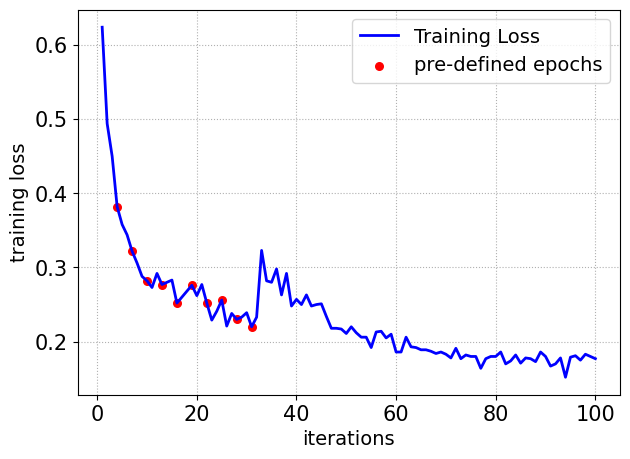

In [10]:
import matplotlib.pyplot as plt


loss_list = np.array(loss_list)
x_list    = np.arange(len(loss_list))+1

prior_x = np.array(epochs_for_priorconstruction) + 1 
prior_y = loss_list[epochs_for_priorconstruction]



fontsiz=14
fig,ax = plt.subplots(figsize=figsiz)

# Plot the training loss over iterations
ax.plot(x_list, loss_list, label='Training Loss', color='blue', linewidth=2)

# Mark specific points, e.g., prior points, using scatter
ax.scatter(prior_x, prior_y, color='red', marker='o', label='pre-defined epochs',s=30)






# Increase the font size of ticks on both axes
plt.tick_params(axis='both', which='major', labelsize=15)

#plt.ylim([0.15,1.5])
#plt.ylim([-0.1,0.87])





end_prior_x = epochs_for_priorconstruction[-1]
y0   = 0.05
eps  = 0.07

# Define start and end points for the horizontal arrows
start_1, end_1 = (1, y0), (end_prior_x+1, y0)
start_2, end_2 = (end_prior_x+1 , y0), (x_list[-1], y0)


mid_1 = 0.5*(start_1[0] + end_1[0])

# Draw the first horizontal arrow
ax.annotate("", xy=end_1, xytext=start_1, 
            arrowprops=dict(arrowstyle="<->", lw=2, color='black'))

# Add text below the first arrow
ax.annotate("MAP", xy=(mid_1, y0-eps), xytext=(mid_1, y0-eps), 
            ha='center', textcoords="data", fontsize=17)



mid_2 = 0.5*(start_2[0] + end_2[0])

# Draw the second horizontal arrow
ax.annotate("", xy=end_2, xytext=start_2, 
            arrowprops=dict(arrowstyle="<->", lw=2, color='black'))

# Add text below the second arrow
ax.annotate("FS-VI", xy=(mid_2, y0-eps), xytext=(mid_2, y0-eps), 
            ha='center', textcoords="data", fontsize=17)






# Add labels for the axes
ax.set_xlabel('iterations',fontsize=fontsiz)
ax.set_ylabel('training loss',fontsize=fontsiz)

# # Add a title to the plot
# ax.set_title('Training Loss vs. Iterations')

# Add a legend to differentiate between the line and the scatter points
ax.legend(fontsize=fontsiz)

# Optional: Grid to better visualize
ax.grid(True, linestyle=':')




# Show the plot
plt.show()


## Predictive distribution of the proposed function-space distribution using learning trajectory 

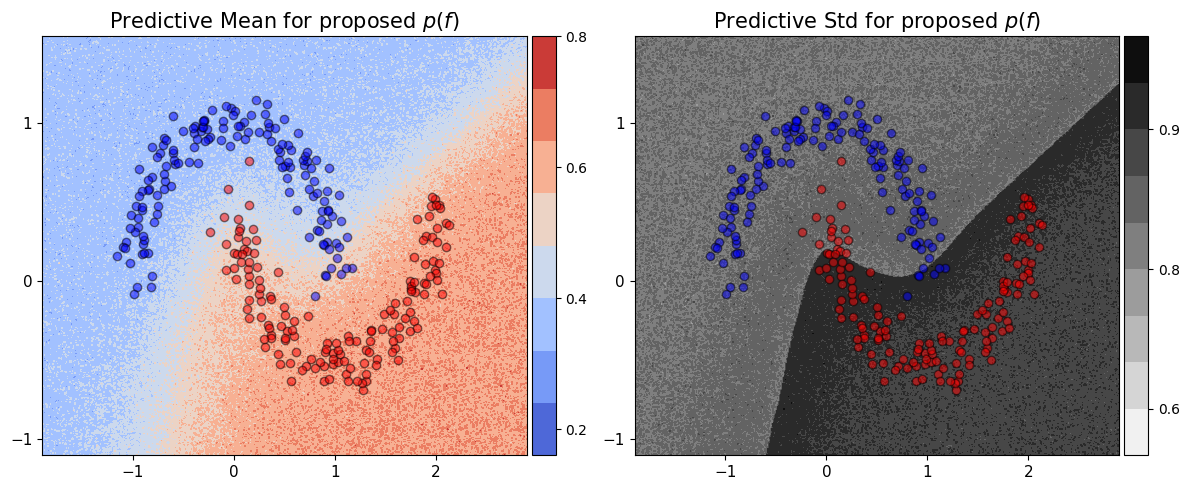

In [11]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
import numpy as np

figsiz = (6*2, 5)


mask = np.asarray(y_vis).astype(bool)

with torch.no_grad():
    outs = model.predict_eval_prior(
        torch.from_numpy(X_grid).float().cuda(),
        use_bayes=use_bayes,
        nfsample=100,
        topk=1
    )
    confidence = (outs.logits.softmax(dim=-1).mean(dim=0))[:, 1]
    std = outs.logits.softmax(dim=-1).std(dim=0)

confidence = confidence.cpu().data.numpy()
std = std.sum(dim=-1).cpu().data.numpy()

z_conf = confidence.reshape(xx.shape)
z_std = std.reshape(xx.shape)

fig, ax = plt.subplots(ncols=2, figsize=figsiz)



# --- Confidence plot ---
cmap_conf = 'coolwarm'
im0 = ax[0].contourf(x_lin, y_lin, z_conf, cmap=cmap_conf)

divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes("right", size="5%", pad=0.05)
cbar0 = fig.colorbar(im0, cax=cax0, alpha=0.25)
cbar0.locator = MaxNLocator(nbins=4)
cbar0.update_ticks()
cbar0.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax[0].set_title(r"Predictive Mean for proposed $p(f)$",fontsize=15)




# --- Standard deviation plot ---
cmap_std = 'gist_yarg'
im1 = ax[1].contourf(x_lin, y_lin, z_std, cmap=cmap_std)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes("right", size="5%", pad=0.05)
cbar1 = fig.colorbar(im1, cax=cax1, alpha=0.25)
cbar1.locator = MaxNLocator(nbins=4)
cbar1.update_ticks()
cbar1.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax[1].set_title(r"Predictive Std for proposed $p(f)$",fontsize=15)

# Axis ticks and scatter
for i in [0, 1]:
    ax[i].set_xticks(np.arange(int(x_lin[0]), int(x_lin[-1])+1))
    ax[i].set_yticks(np.arange(int(y_lin[0]), int(y_lin[-1])+1))
    ax[i].tick_params(axis='both', which='major', labelsize=11)
    ax[i].scatter(X_vis[mask, 0], X_vis[mask, 1], color='red', alpha=0.5, edgecolors='k')
    ax[i].scatter(X_vis[~mask, 0], X_vis[~mask, 1], color='blue', alpha=0.5, edgecolors='k')

plt.tight_layout()
# plt.savefig("your_output_path.pdf", dpi=300, bbox_inches='tight')
plt.show()


## Predictive distribution of variational function-space distribution m

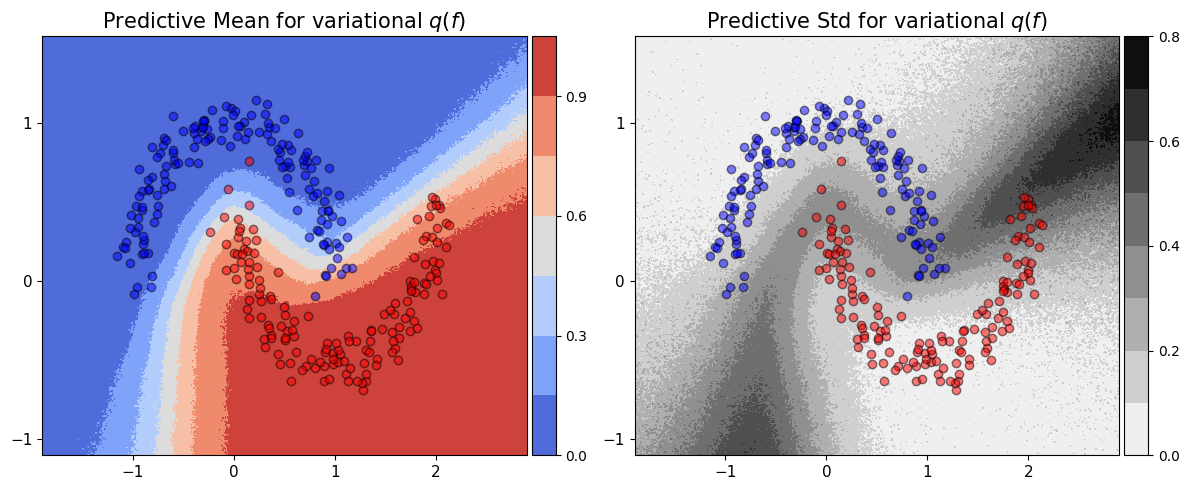

In [12]:

mask = np.asarray(y_vis).astype(bool)

with torch.no_grad():
    outs = model.predict_eval(
        torch.from_numpy(X_grid).float().cuda(),
        use_bayes=use_bayes,
        nfsample=100,
        topk=1
    )
    confidence = (outs.logits.softmax(dim=-1).mean(dim=0))[:, 1]
    std = outs.logits.softmax(dim=-1).std(dim=0)

confidence = confidence.cpu().data.numpy()
std = std.sum(dim=-1).cpu().data.numpy()

z_conf = confidence.reshape(xx.shape)
z_std = std.reshape(xx.shape)






fig, ax = plt.subplots(ncols=2, figsize=figsiz)

# --- Confidence plot ---
cmap_conf = 'coolwarm'
im0 = ax[0].contourf(x_lin, y_lin, z_conf, cmap=cmap_conf)

divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes("right", size="5%", pad=0.05)
cbar0 = fig.colorbar(im0, cax=cax0, alpha=0.25)
cbar0.locator = MaxNLocator(nbins=4)
cbar0.update_ticks()
cbar0.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax[0].set_title(r"Predictive Mean for variational $q(f)$",fontsize=15)

# --- Standard deviation plot ---
cmap_std = 'gist_yarg'
im1 = ax[1].contourf(x_lin, y_lin, z_std, cmap=cmap_std)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes("right", size="5%", pad=0.05)
cbar1 = fig.colorbar(im1, cax=cax1, alpha=0.25)
cbar1.locator = MaxNLocator(nbins=4)
cbar1.update_ticks()
cbar1.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
ax[1].set_title(r"Predictive Std for variational $q(f)$",fontsize=15)

# Axis ticks and scatter
for i in [0, 1]:
    ax[i].set_xticks(np.arange(int(x_lin[0]), int(x_lin[-1])+1))
    ax[i].set_yticks(np.arange(int(y_lin[0]), int(y_lin[-1])+1))
    ax[i].tick_params(axis='both', which='major', labelsize=11)
    ax[i].scatter(X_vis[mask, 0], X_vis[mask, 1], color='red', alpha=0.5, edgecolors='k')
    ax[i].scatter(X_vis[~mask, 0], X_vis[~mask, 1], color='blue', alpha=0.5, edgecolors='k')

plt.tight_layout()
plt.show()
